In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 



In [2]:
# Plotting setup

from my_plot import set_size
import seaborn as sns
width =  508.0
widthcol = 244
plt.rcParams['font.size']=12

colors1=sns.color_palette("rocket",4) #personal fav 
colors2=sns.color_palette("mako",4) #also nice
colors3 = plt.colormaps['Spectral'].resampled(4)

colors4 = ['#c3121e', '#0348a1', '#ffb01c', '#027608', '#0193b0', '#9c5300', '#949c01', '#7104b5']
#            0sangre,   1neptune,  2pumpkin,  3clover,   4denim,    5cocoa,    6cumin,    7berry


#%matplotlib widget

In [3]:
# Function to format numbers in scientific notation for plots

f =  ScalarFormatter(useOffset=False, useMathText=True)
f.set_scientific(True)
f.set_powerlimits((0, 0))

def sci_notation(x):
    if x == 0:
        return "0"
    else:
        formatted = f"{x:.2e}"  # Converte in notazione scientifica
        coefficient, exponent = formatted.split('e')
        exponent = int(exponent)  # Converti l'esponente a intero
        return f"${coefficient} \\times 10^{{{exponent}}}$"  # Notazione LaTeX

In [4]:
# Initalizing constants

K = 1.380649e-23 # J / K
vc = 299792458 # m / s
h_pl = 6.62607015e-34 # J*s
T_cmb = 2.726 # K
omegab_h2 = 0.0224

I0 =(2*K**3*T_cmb**3)/(vc**2*h_pl**2)*1e26 # in Jy / sr
print(I0/1e6, "MJy sr^-1")

270.2115654196308 MJy sr^-1


In [5]:
# Normalised distortion spectral shapes

def nbb(x): return (1/(np.exp(x)-1)) # * I0
def G(x): return (x * np.exp(x) * nbb(x)**2 )   # intensity not occupation number /4.0 * I0
def Y(x): return x**3 * I0 * (G(x) * ( x * ( 2 * nbb(x) + 1 ) - 4 ) ) / 4.0
def M(x): return x**3 * I0 * (G(x) * ( 1.0 / 2.1923 - 1.0 / x ) ) * 1.401
def D(x): return x**3 * I0 * (G(x) * 1.6449 / (3*2.4041) - nbb(x) / x) / 0.5421 

In [6]:
def extract_Ix_from_files(folder_path, pattern="Dn_final.photon_conversion.dark-photon.dat"):
    """Extract x and Ix data from files in a folder, regular heating mode wiith no batch"""
    folder = Path(folder_path) / "PDE-non-linear"
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
    
    data = np.loadtxt(file_path, comments='#')  
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 5])  # All Ix values from column 5

    return np.array(x), np.array(Ix)

In [7]:
def extract_Ix_from_files_FH(folder_path, pattern="full_spectrum.dat_ymax15_y_bg.dat"):
    """Extract x and Ix data from files in a folder, FH module"""
    folder = Path(folder_path) / "FH" 
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
  
    data = np.loadtxt(file_path, comments='#')
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 1])  # All Ix values from column 5
    
    return np.array(x), np.array(Ix)

In [8]:
x , Ix = extract_Ix_from_files("../Data/Test-code/Photon-conversion/") # [I] = Jy / sr
x_FH , Ix_FH = extract_Ix_from_files_FH("../Data/Test-code/Photon-conversion-FH/")
x_Mnum , Ix_Mnum = extract_Ix_from_files_FH("../Data/Test-code/Photon-conversion-FH-Mnum/")

In [10]:

# Find common frequency range
xmin = max(x.min(), x_FH.min(), x_Mnum.min())
xmax = min(x.max(), x_FH.max(), x_Mnum.max())

# Mask arrays to common range
mask_x = (x >= xmin) & (x <= xmax)
mask_x_FH = (x_FH >= xmin) & (x_FH <= xmax)
mask_x_Mnum = (x_Mnum >= xmin) & (x_Mnum <= xmax)
x_common = np.linspace(xmin, xmax, 500)

# Cubic spline fits (exact interpolation for clean simulation data)
spline_Ix = CubicSpline(x[mask_x], Ix[mask_x])
spline_Ix_FH = CubicSpline(x_FH[mask_x_FH], Ix_FH[mask_x_FH])
spline_Ix_Mnum = CubicSpline(x_Mnum[mask_x_Mnum], Ix_Mnum[mask_x_Mnum])

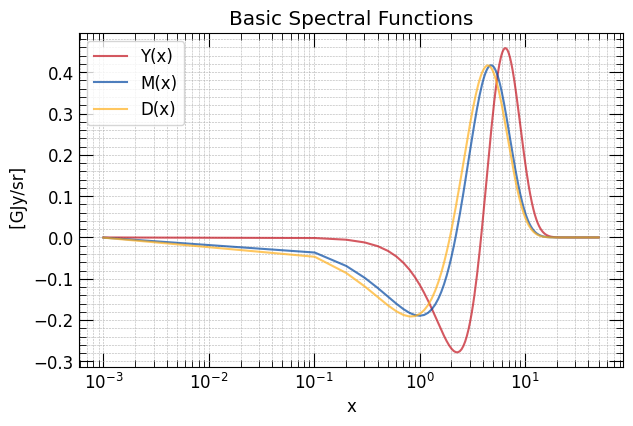

In [11]:
# Plot Analytical Spectra
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, Y(x_common) / 1e9, label="Y(x)", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common, M(x_common) / 1e9, label="M(x)", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_common, D(x_common) / 1e9, label="D(x)", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
#ax1.set_xlim([1e+0, 5e+3])

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [GJy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Basic Spectral Functions")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

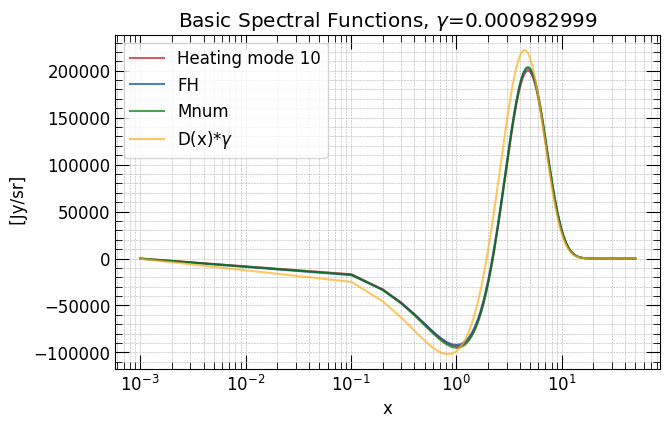

In [12]:

# Plot Analytical Spectra
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, spline_Ix(x_common), label="Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common, spline_Ix_FH(x_common), label="FH", color=colors4[1], alpha=0.7, linestyle="-")
ax1.plot(x_common, spline_Ix_Mnum(x_common), label="Mnum", color=colors4[3], alpha=0.7, linestyle="-")
ax1.plot(x_common, 0.5421 * D(x_common) * gamma, label="D(x)*$\\gamma$", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
#ax1.set_xlim([1e+0, 5e+3])

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [Jy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Basic Spectral Functions, $\\gamma$="+str(gamma))
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

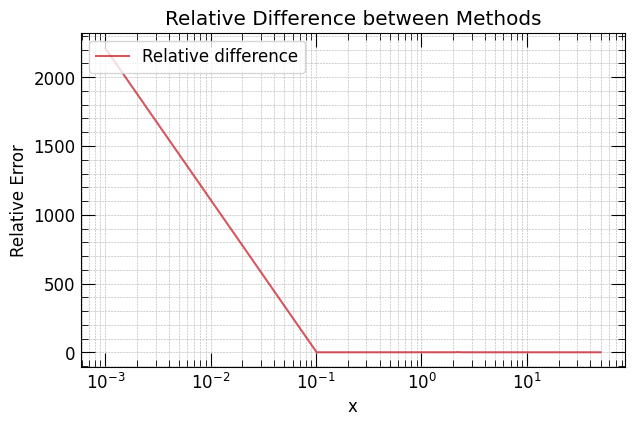

In [ ]:
# Plot Relative Difference: FH vs Heating mode 10
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_FH(x_common)) / np.abs(spline_Ix(x_common)), label="FH vs Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_xlabel("x")
ax1.set_title("Relative Difference: FH vs Heating mode 10")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
ax1.legend(loc='upper left')

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True, labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

#plt.savefig('outputs/relative_difference_FH.pdf', dpi=300, bbox_inches="tight")
plt.show()


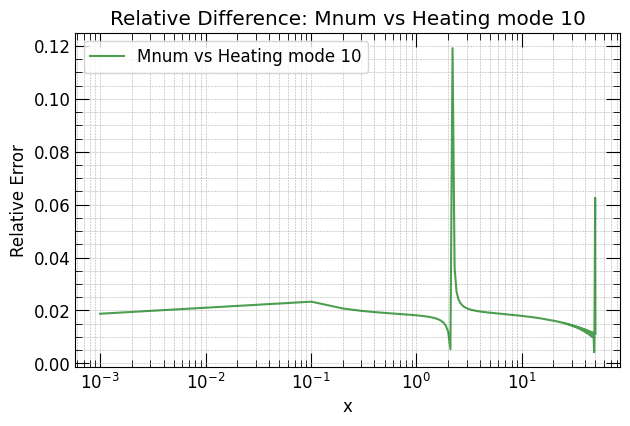

In [15]:
# Plot Relative Difference: Mnum vs Heating mode 10
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_Mnum(x_common)) / np.abs(spline_Ix(x_common)), label="Mnum vs Heating mode 10", color=colors4[3], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_xlabel("x")
ax1.set_title("Relative Difference: Mnum vs Heating mode 10")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
ax1.legend(loc='upper left')

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True, labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

#plt.savefig('outputs/relative_difference_Mnum.pdf', dpi=300, bbox_inches="tight")
plt.show()


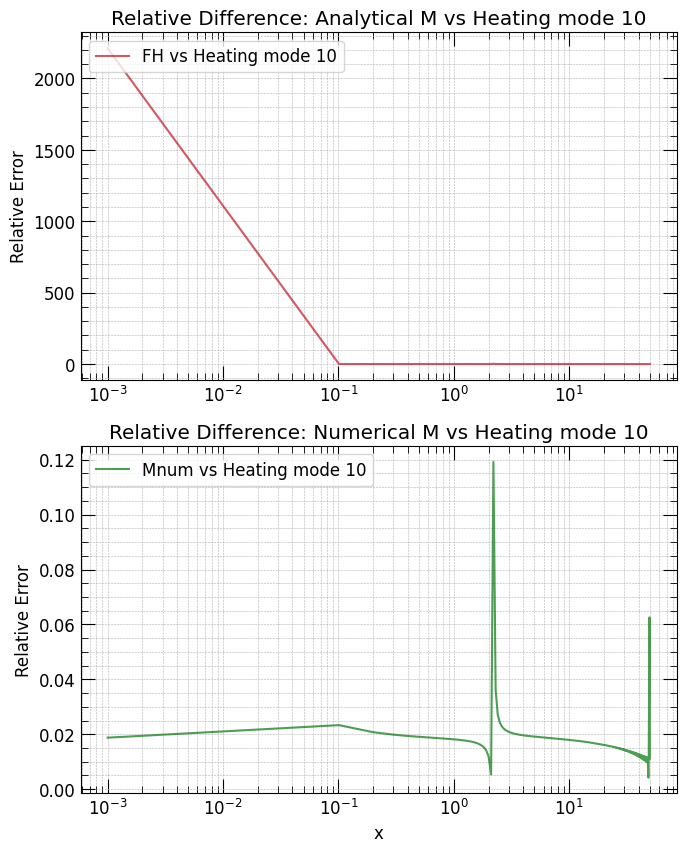

In [17]:
# Plot Relative Differences (Combined)
gamma = 0.000982999
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(set_size(width)[0], set_size(width)[1]*2))

# Top plot: FH vs Heating mode 10
ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_FH(x_common)) / np.abs(spline_Ix(x_common)), label="FH vs Heating mode 10", color=colors4[0], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_title("Relative Difference: Analytical M vs Heating mode 10")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
ax1.legend(loc='upper left')
ax1.minorticks_on()
ax1.tick_params(direction='in',right=True, top=True, labelsize=12)
ax1.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
ax1.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
ax1.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

# Bottom plot: Mnum vs Heating mode 10
ax2.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_Mnum(x_common)) / np.abs(spline_Ix(x_common)), label="Mnum vs Heating mode 10", color=colors4[3], alpha=0.7, linestyle="-")

ax2.set_xscale('log')
ax2.set_ylabel("Relative Error")
ax2.set_xlabel("x")
ax2.set_title("Relative Difference: Numerical M vs Heating mode 10")
ax2.grid(True, which='both', linestyle='--', linewidth=0.4)
ax2.legend(loc='upper left')
ax2.minorticks_on()
ax2.tick_params(direction='in',right=True, top=True, labelsize=12)
ax2.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
ax2.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
ax2.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

plt.tight_layout()
#plt.savefig('outputs/relative_differences.pdf', dpi=300, bbox_inches="tight")
plt.show()
